In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import PchipInterpolator

from igs_ga.optimization.modo import Preferendus


In [2]:
# Define preference function points for interpolation
x_points_profit = [240000, 450000, 1200000]
p_points_profit = [0, 65, 100]

x_points_co2 = [90000, 200000, 750000]
p_points_co2 = [100, 30, 0]

x_points_shopping = [45000, 200000, 360000]
p_points_shopping = [0, 80, 100]

# Create preference functions using PchipInterpolator for better consistency with other examples
stakeholder_preferences = {
    1: {
        "1_profit": lambda p: PchipInterpolator(x_points_profit, p_points_profit)(p),
        "2_co2": lambda c: PchipInterpolator(x_points_co2, p_points_co2)(c),
        "3_shopping": lambda s: PchipInterpolator(x_points_shopping, p_points_shopping)(s),
    },
}

# Set objective weights
objective_weights = {
    1: {"1_profit": 0.25, "2_co2": 0.50, "3_shopping": 0.25},
}

In [3]:
# Set optimization options
optimization_options = {
    'population_size': 1000,
    'generations': 20,
    'mutation_rate': 0.8,
    'hall_of_fame_size':50,
}

@Preferendus(
    preference_functions=stakeholder_preferences,
    stakeholder_weights=[1.0],
    variable_types=[float, float],
    value_range=[(0.0, 5000.0), (0.0, 7000.0)],
    objective_weights=objective_weights,
    optimization_options=optimization_options,
    constraints=[
        lambda x: x[0] + x[1] <= 10000,  #: total area <= 10000
        lambda x: (x[0] + x[1]) >= 3000,  #: total area >= 3000
    ]
)
def run_simulation(x):
    """Objective function that calculates the three objectives for the shopping mall problem.

    :param x: Design variables [x1, x2] where x1 and x2 are the areas in m²
    :return: None, None, plus the three objective values
    """
    # Calculate the objective values
    profit = 160 * x[0] + 80 * x[1]
    co2 = 120 * x[0] + 30 * x[1]
    shopping = 15 * x[0] + 45 * x[1]

    return None, None, profit, co2, shopping

In [4]:
# Run the optimization
result = run_simulation([2500, 2500])  # Initial guess
print(f"Optimal variables: x1 = {round(result['x_opt'][0], 2)}m², "
      f"x2 = {round(result['x_opt'][1], 2)}m² "
      f"(sum = {round(sum(result['x_opt']))}m²)")
print(f"Utility: {result['utility']}")

Generation  Best score  Infeasible  Stall   Gene mutation rate
1           100.00      544         0       0.006494    
2           100.00      60          1       0.006467    
3           100.00      34          0       0.006489    
4           100.00      13          0       0.006496    
5           100.00      10          1       0.006546    
6           100.00      4           0       0.006554    
7           100.00      5           1       0.006522    
8           100.00      3           2       0.006525    
9           100.00      4           0       0.006521    
10          100.00      6           0       0.006552    
11          100.00      5           1       0.006558    
12          100.00      4           2       0.006613    
13          100.00      0           3       0.006653    
14          100.00      0           4       0.006653    
15          100.00      3           5       0.00669     
16          100.00      0           6       0.006656    
17          100.00      0

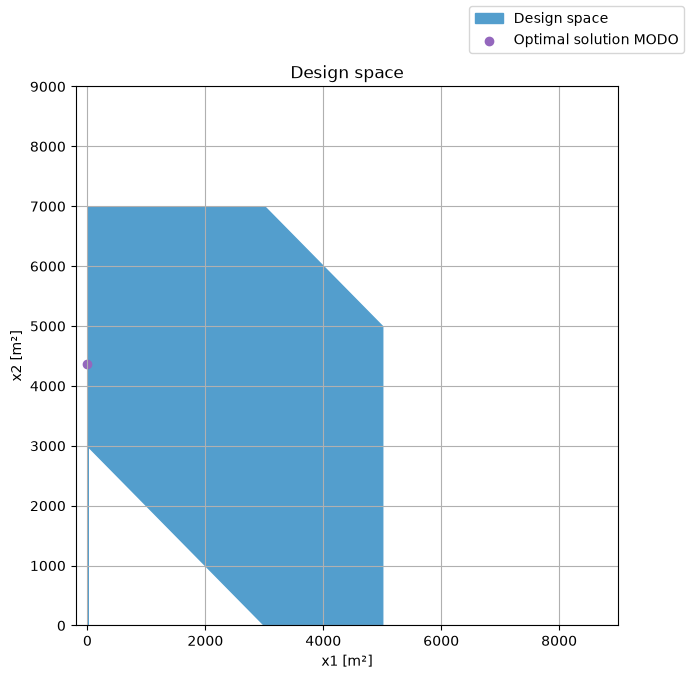

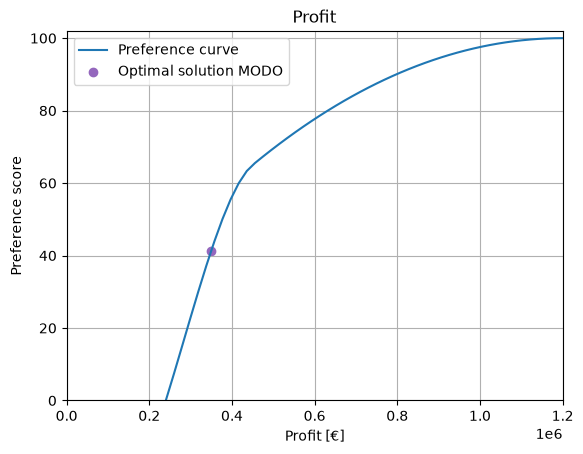

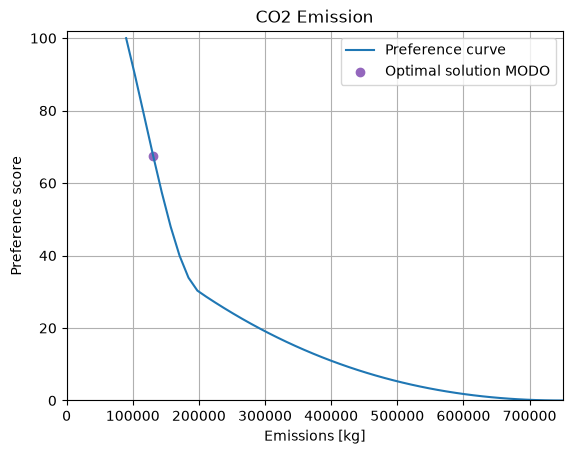

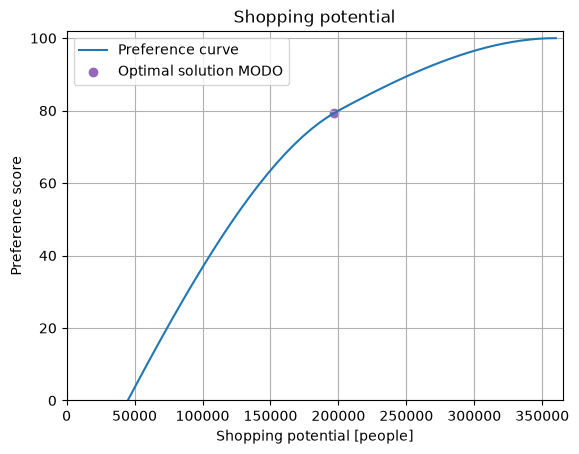

In [5]:
# Extract optimal design variables for plotting
design_variables = result['x_opt']

# Calculate objective values for the optimal solution
profit_optimal = 160 * design_variables[0] + 80 * design_variables[1]
co2_optimal = 120 * design_variables[0] + 30 * design_variables[1]
shopping_optimal = 15 * design_variables[0] + 45 * design_variables[1]

# Create arrays for plotting continuous preference curves
c1 = np.linspace(min(x_points_profit), max(x_points_profit))
c2 = np.linspace(min(x_points_co2), max(x_points_co2))
c3 = np.linspace(min(x_points_shopping), max(x_points_shopping))

# Create preference functions for plotting
p1 = PchipInterpolator(x_points_profit, p_points_profit)
p2 = PchipInterpolator(x_points_co2, p_points_co2)
p3 = PchipInterpolator(x_points_shopping, p_points_shopping)

# Calculate preference values for the optimal solution
p1_res = p1(profit_optimal)
p2_res = p2(co2_optimal)
p3_res = p3(shopping_optimal)

# Create figure that shows the results in the design space
fig, ax = plt.subplots(figsize=(7, 7))
ax.set_xlim((-200, 9000))
ax.set_ylim((0, 9000))
ax.set_xlabel('x1 [m²]')
ax.set_ylabel('x2 [m²]')
ax.set_title('Design space')

# Define corner points of design space
x_fill = [0, 3000, 5000, 5000, 3000, 0]
y_fill = [7000, 7000, 5000, 0, 0, 3000]

ax.fill_between(x_fill, y_fill, color='#539ecd', label='Design space')
ax.scatter(design_variables[0], design_variables[1], color='tab:purple', label='Optimal solution MODO')

ax.grid()  # show grid
fig.legend()  # show legend

# Plot preference curves and optimal results
fig = plt.figure()
ax1 = fig.add_subplot(1, 1, 1)
ax1.plot(c1, p1(c1), label='Preference curve')
ax1.scatter(profit_optimal, p1_res, label='Optimal solution MODO', color='tab:purple')
ax1.set_xlim((0, 1200000))
ax1.set_ylim((0, 102))
ax1.set_title('Profit')
ax1.set_xlabel('Profit [€]')
ax1.set_ylabel('Preference score')
ax1.grid()
ax1.legend()

fig = plt.figure()
ax2 = fig.add_subplot(1, 1, 1)
ax2.plot(c2, p2(c2), label='Preference curve')
ax2.scatter(co2_optimal, p2_res, label='Optimal solution MODO', color='tab:purple')
ax2.set_xlim((0, 750000))
ax2.set_ylim((0, 102))
ax2.set_title('CO2 Emission')
ax2.set_xlabel('Emissions [kg]')
ax2.set_ylabel('Preference score')
ax2.grid()
ax2.legend()

fig = plt.figure()
ax3 = fig.add_subplot(1, 1, 1)
ax3.plot(c3, p3(c3), label='Preference curve')
ax3.scatter(shopping_optimal, p3_res, label='Optimal solution MODO', color='tab:purple')
ax3.set_xlim((0, 365000))
ax3.set_ylim((0, 102))
ax3.set_title('Shopping potential')
ax3.set_xlabel('Shopping potential [people]')
ax3.set_ylabel('Preference score')
ax3.grid()
ax3.legend()

plt.show()